# 07 · Apriori pattern mining of drying (Fig. 4)
**Method** (`src/pattern_mining.py`). Each source is a transaction of items: tertiles of interpretable
GIS covariates, the landscape type and survey categorical attributes. Frequent itemsets via apriori
(min support 2 %, <= 3 antecedent items) -> rules *A -> dried* / *A -> active*; one-sided Fisher tests
with BH-FDR; productive rules only; ward-stratified Mantel-Haenszel odds ratios with a second BH screen;
replication on held-out spatial blocks; ranking by WRAcc. X6 adds FDR control to the candidate
Simpson-type reversals. Running this notebook re-mines everything (a few minutes).

In [1]:
import logging, os, sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s [%(levelname)s] %(message)s", stream=sys.stdout, force=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

M = ROOT / "results/metrics"
F = ROOT / "results/figures"

def table(name, **kw):
    return pd.read_csv(M / name, **kw).round(4)

def fig(name, width=1100):
    display(Image(filename=str(F / name), width=width))

In [2]:
from src.pattern_mining import run as run_mining
run_mining()

2026-11-10 16:01:25,158 [INFO] consequent=dried: 66563 itemsets, 15744 significant, 3321 significant+productive


2026-11-10 16:02:22,846 [INFO] consequent=active: 66563 itemsets, 18580 significant, 2337 significant+productive


2026-11-10 16:02:55,755 [INFO] 
                     item  support  drying_rate_if_seasonal  drying_rate_if_perennial  mh_or_ward  mh_ci_low  mh_ci_high  share_wards_lift_gt1  n_wards_evaluable
0  flow=seasonal (survey)    0.163                    0.631                     0.196       6.945      5.776        8.35                 0.882                 51


2026-11-10 16:02:55,850 [INFO] 
  consequent  n_rules  n_ward_robust  n_reversed_within_wards  median_heldout_replication  median_share_wards_lift_gt1
0     active     2337           1903                        4                         1.0                        0.778
1      dried     3321           2613                       11                         1.0                        0.684


2026-11-10 16:02:55,857 [INFO] 
     consequent                                                      antecedent  support  confidence   lift  q_bh  mh_or_ward  mh_ci_low  mh_ci_high  share_wards_lift_gt1  heldout_replication
0         dried                                     climatic water deficit=high    0.318       0.388  1.453   0.0       1.513      1.193       1.918                 0.667                  1.0
3321     active                                       annual precipitation=high    0.328       0.843  1.150   0.0       1.106      0.802       1.525                 0.444                  1.0
3322     active                                              soil moisture=high    0.279       0.855  1.167   0.0       1.823      1.313       2.531                 0.647                  1.0
3323     active                                      climatic water deficit=low    0.423       0.809  1.104   0.0       1.708      1.259       2.317                 0.667                  0.8
1       

In [3]:
from src.revision_experiments import run as run_experiments
run_experiments(only=["X6"])

2026-11-10 16:02:56,028 [INFO] X6 ...


2026-11-10 16:02:56,070 [INFO] 
  consequent  n_rules  n_ward_robust  n_reversal_ci  n_reversal_fdr  median_heldout_replication  share_heldout_all_folds  share_heldout_4of5  share_ward_robust
0     active     2337           1903              4               0                         1.0                   0.7706              0.8639             0.8143
1      dried     3321           2613             11               0                         1.0                   0.5700              0.7790             0.7868


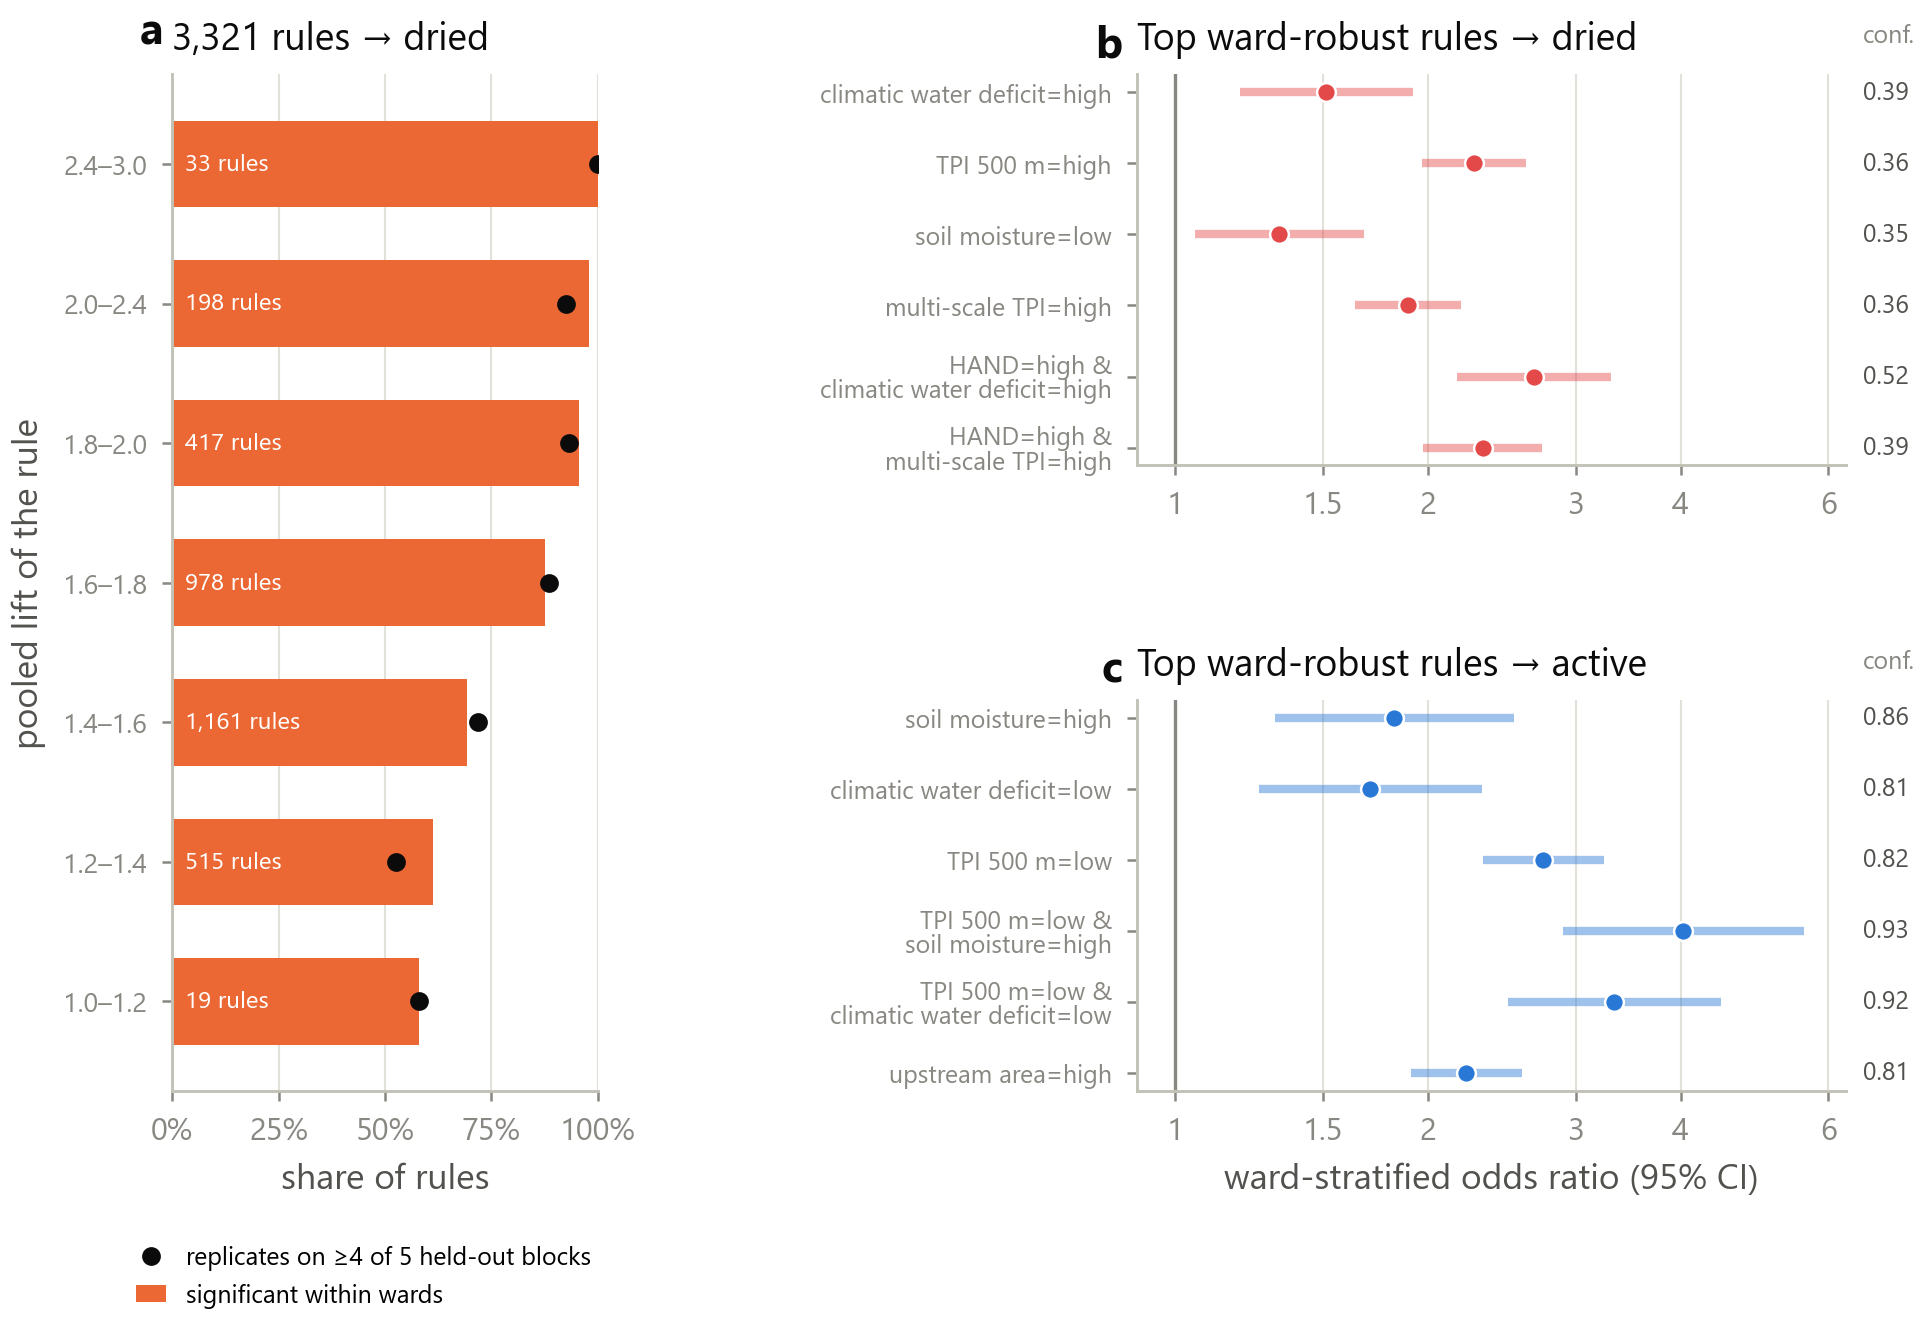

In [4]:
fig("fig4_rules.png")

In [5]:
display(table("pm_drying_rules_summary.csv"))
display(table("x6_reversals_fdr.csv"))
table("pm_seasonal_flag.csv")

,consequent,n_rules,n_ward_robust,n_reversed_within_wards,median_heldout_replication,median_share_wards_lift_gt1
0,active,2337,1903,4,1.0,0.7778
1,dried,3321,2613,11,1.0,0.6842


,consequent,n_rules,n_ward_robust,n_reversal_ci,n_reversal_fdr,median_heldout_replication,share_heldout_all_folds,share_heldout_4of5,share_ward_robust
0,active,2337,1903,4,0,1.0,0.7706,0.8639,0.8143
1,dried,3321,2613,11,0,1.0,0.5700,0.7790,0.7868


,item,support,drying_rate_if_seasonal,drying_rate_if_perennial,mh_or_ward,mh_ci_low,mh_ci_high,share_wards_lift_gt1,n_wards_evaluable
0,flow=seasonal (survey),0.1635,0.6312,0.1963,6.9448,5.7763,8.3495,0.8824,51


## Top rules for drying and for activity (ranked by WRAcc)

In [6]:
r = table("pm_drying_rules.csv")
cols = ["antecedent", "n", "support", "confidence", "lift", "q_bh", "mh_or_ward", "mh_ci_low",
        "mh_ci_high", "heldout_replication"]
display(r[r.consequent == "dried"].sort_values("wracc", ascending=False)[cols].head(15))
r[r.consequent == "active"].sort_values("wracc", ascending=False)[cols].head(10)

,antecedent,n,support,confidence,lift,q_bh,mh_or_ward,mh_ci_low,mh_ci_high,heldout_replication
0,climatic water deficit=high,1810,0.3182,0.3884,1.4527,0.0,1.5128,1.1928,1.9185,1.0
1,TPI 500 m=high,1897,0.3335,0.3600,1.3467,0.0,2.2700,1.9704,2.6152,1.0
2,soil moisture=low,2133,0.3749,0.3479,1.3011,0.0,1.3305,1.0562,1.6762,0.8
3,multi-scale TPI=high,1875,0.3296,0.3589,1.3425,0.0,1.8932,1.6373,2.1890,1.0
4,HAND=high & climatic water deficit=high,663,0.1165,0.5219,1.9520,0.0,2.6751,2.1660,3.3039,1.0
5,HAND=high & multi-scale TPI=high,1317,0.2315,0.3910,1.4626,0.0,2.3261,1.9758,2.7385,1.0
6,HAND=high,1896,0.3333,0.3523,1.3178,0.0,2.0727,1.7763,2.4185,1.0
7,landscape type=T5,1514,0.2661,0.3686,1.3785,0.0,1.5775,1.3016,1.9119,0.8
9,NDVI trend 2001-23=high & climatic water deficit=high,834,0.1466,0.4460,1.6683,0.0,1.5314,1.2469,1.8808,1.0
8,climatic water deficit=high & multi-scale TPI=high,572,0.1005,0.5280,1.9748,0.0,2.4221,1.9469,3.0132,1.0


,antecedent,n,support,confidence,lift,q_bh,mh_or_ward,mh_ci_low,mh_ci_high,heldout_replication
3321,annual precipitation=high,1865,0.3278,0.8429,1.1505,0.0,1.1058,0.8021,1.5246,1.0
3322,soil moisture=high,1588,0.2791,0.8552,1.1672,0.0,1.8233,1.3134,2.5313,1.0
3323,climatic water deficit=low,2408,0.4233,0.8090,1.1042,0.0,1.7076,1.2586,2.3168,0.8
3324,TPI 500 m=low,1896,0.3333,0.8244,1.1252,0.0,2.7452,2.3233,3.2437,1.0
3325,TPI 500 m=low & soil moisture=high,771,0.1355,0.9287,1.2676,0.0,4.0311,2.8968,5.6096,1.0
3326,TPI 500 m=low & climatic water deficit=low,821,0.1443,0.9160,1.2502,0.0,3.3355,2.4890,4.4698,1.0
3327,upstream area=high,1893,0.3327,0.8104,1.1061,0.0,2.2231,1.9088,2.5893,1.0
3328,NDVI=high,1897,0.3335,0.8092,1.1045,0.0,1.5061,1.2911,1.7570,1.0
3329,climatic water deficit=low & population 1 km=low,907,0.1594,0.8920,1.2174,0.0,1.6803,1.2491,2.2604,1.0
3330,cropland share (WorldCover)=low & tree share (WorldCover)=high,1387,0.2438,0.8335,1.1376,0.0,1.6462,1.3675,1.9818,1.0


## Candidate Simpson-type reversals (none survives FDR control)

In [7]:
r[r.reverses_within_wards][["consequent"] + cols].sort_values("support", ascending=False)

,consequent,antecedent,n,support,confidence,lift,q_bh,mh_or_ward,mh_ci_low,mh_ci_high,heldout_replication
14,dried,elevation=low,1899,0.3338,0.3428,1.2822,0.0000,0.8025,0.6647,0.9689,0.8000
1329,dried,population 1 km=high & precipitation trend=low & slope=low,650,0.1143,0.3262,1.2199,0.0016,0.6511,0.4908,0.8639,1.0000
2370,dried,climatic water deficit=low & population 1 km=high & precipitation trend=low,498,0.0875,0.3193,1.1942,0.0196,0.5671,0.3573,0.9001,0.6667
4416,active,NDVI trend 2001-23=low & climatic water deficit=low & population 1 km=mid,303,0.0533,0.8251,1.1262,0.0005,0.6835,0.4704,0.9931,0.7500
2963,dried,forest loss 2001-14=none & precipitation trend=mid & soil clay=low,290,0.0510,0.3345,1.2511,0.0262,0.5551,0.3898,0.7904,1.0000
2206,dried,annual precipitation=low & climatic water deficit=low & soil moisture=mid,249,0.0438,0.3775,1.4120,0.0005,0.5996,0.3771,0.9535,0.6667
2205,dried,annual precipitation=low & climatic water deficit=low & population 1 km=high,249,0.0438,0.3775,1.4120,0.0005,0.6114,0.3852,0.9705,0.6667
2250,dried,annual precipitation=low & climatic water deficit=low & precipitation trend=low,247,0.0434,0.3765,1.4083,0.0006,0.5955,0.3747,0.9466,0.6667
3062,dried,landscape type=T2 & multi-scale TPI=mid,247,0.0434,0.3401,1.2720,0.0275,0.6561,0.4555,0.9448,1.0000
4611,active,climatic water deficit=low & population 1 km=mid & precipitation trend=low,232,0.0408,0.8405,1.1472,0.0004,0.5801,0.3710,0.9070,1.0000
